In [7]:
import pandas as pd

X = pd.read_csv('/content/data/X_features.csv')
y = pd.read_csv('/content/data/y_target.csv').squeeze()  # 1차원 Series 형태로 변환
# y


In [8]:
!pip install xgboost

from sklearn.model_selection import cross_validate, KFold, TimeSeriesSplit
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

/bin/bash: line 1: xgboost: command not found


In [10]:
# 모델 정의
models = {
    'Linear'      : LinearRegression(),
    'RandomForest': RandomForestRegressor(n_estimators=300, random_state=0),
    'XGBoost'     : XGBRegressor(n_estimators=500, learning_rate=0.05,
                                 max_depth=4, random_state=0),
}

# 교차검증
cv = KFold(n_splits=5, shuffle=True, random_state=0)
# 시간 순서를 지켜야 하면 : cv = TimeSeriesSplit(n_splits=5)


In [ ]:
rows = []
for name, model in models.items():
    # scoring : 채점 기준 -> tuple 안에 여러개를 넣을 수 있다.
    # neg_root_mean_squared_error : 음수 RMSE(평균 제곱근 오차)
    # -> scikit-learn 에서는 클수록 좋다는 규칙이 있는데, RMSE 는 작을수록 좋다. 그래서 반전을 위해 음수 사용
    # r2 : 우리 모델이 몇 퍼센트(%)나 똑똑하게 설명해 냈는지
    r = cross_validate(model, X, y, cv=cv, scoring=('neg_root_mean_squared_error', 'r2'))
    # 각 Fold의 학습이 아닌 검증 점수가 필요 하므로 test_ 항목에서 가져옴
    rows.append({'model': name,
                 # test_neg_root_mean_squared_error 의 평균에 - 값을 다시 양으로 변경
                 'RMSE(mm)': -r['test_neg_root_mean_squared_error'].mean(),
                 # r2 값 평균
                 'R2': r['test_r2'].mean()})

result = pd.DataFrame(rows).sort_values('RMSE(mm)')
print(result)          # → 성능비교표 (산출물)

          model  RMSE(mm)        R2
0        Linear  0.004025  0.934886
2       XGBoost  0.004675  0.912121
1  RandomForest  0.005072  0.896720


In [ ]:
# 특징 중요도 해석
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# 데이터 분할
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

# 모델 학습
model = XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=4,random_state=0)
best = model.fit(x_train, y_train)

# permutation_importance: 변수 값을 무작위로 섞어 중요도를 계산해 주는 함수
# n_repeats=10: 각 특성마다 무작위 섞기를 10번씩 반복
pi = permutation_importance(best, x_test, y_test, n_repeats=10, random_state=0)

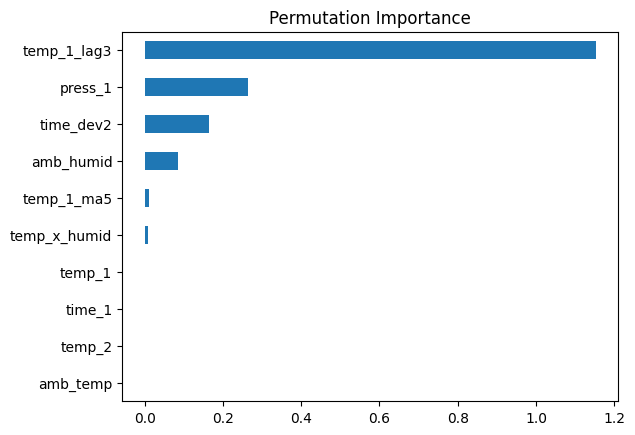

In [ ]:
# pi.importances_mean:모델 성능(R2)이 평균적으로 얼마나 떨어졌는지를 담은 배열
# index=X.columns 입력 데이터프레임 X가 가지고 있는 컬럼 이름 목록을 붙임
# sort_values() : 정렬
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values()
imp.plot.barh(title='Permutation Importance')
plt.show()

In [15]:
# 다음에 모델 활용을 위해 저장
from joblib import dump
# 학습한 알고리즘을 저장하여 다른 곳에서 사용할 수도 있다.
dump(best, '/content/data/best.joblib')

['/content/data/best.joblib']